# Vortex lattice analysis of a swept, tapered, twisted wing

Walkthrough of the study using the `vlmwing` package. Every number and figure here is produced by
the code in `src/vlmwing/`, which is covered by the test suite. Run `vlmwing` from a terminal to
reproduce the same results without the notebook.

**Baseline wing:** S = 1 m², A = 15, λ = 0.65, Λ<sub>c/4</sub> = 12°, tip twist −5°, NACA 3217,
one chordwise panel and 20 spanwise panels.

In [1]:
import sys

if "google.colab" in sys.modules:  # Colab: install the package from GitHub
    %pip install -q git+https://github.com/CPesquero/vlm-wing-aerodynamics.git

import numpy as np

import vlmwing as v
from vlmwing import plots

wing = v.BASELINE
alphas = np.array(v.XFLR5_ALPHAS)  # -12, -6, 0, 6, 12 deg

## 1. Geometry

The leading-edge sweep follows from the quarter-chord sweep and the taper. The aerodynamic center
sits at a quarter of the mean aerodynamic chord, at the spanwise station of that chord.

span            b    = 3.873 m
root / tip chord     = 0.313 / 0.203 m
taper ratio     λ    = 0.6486
aspect ratio    A    = 15.01
LE sweep        Λ_LE = 12.78°  (Λ_c/4 = 12°)
MAC                  = 0.2619 m
aerodynamic center   = (0.2694, 0.8994) m
camber slope at 3c/4 = -0.0516


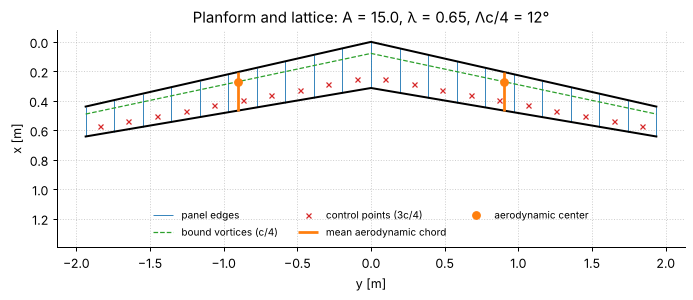

In [2]:
print(f"span            b    = {wing.span:.3f} m")
print(f"root / tip chord     = {wing.root_chord:.3f} / {wing.tip_chord:.3f} m")
print(f"taper ratio     λ    = {wing.taper:.4f}")
print(f"aspect ratio    A    = {wing.aspect_ratio:.2f}")
print(f"LE sweep        Λ_LE = {wing.sweep_le_deg:.2f}°  (Λ_c/4 = {wing.sweep_c4_deg:.0f}°)")
print(f"MAC                  = {wing.mac:.4f} m")
print(f"aerodynamic center   = ({wing.x_ac:.4f}, {wing.y_ac:.4f}) m")
print(f"camber slope at 3c/4 = {wing.camber_slope:.4f}")
plots.planform(wing);

## 2. Sectional lift

Each panel carries a horseshoe vortex on its quarter-chord line. Flow tangency is imposed at the
three-quarter-chord control point, including the local twist and the camber-line slope, and the
Kutta–Joukowski theorem turns circulation into sectional lift.

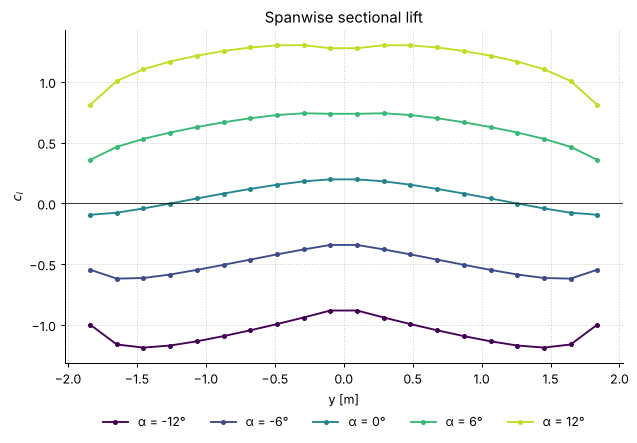

In [3]:
sol = v.solve(wing, alphas, n_panels=20)
plots.lift_distribution(sol);

The dip at the root comes from the sweep: each half-wing induces downwash on the other near the
plane of symmetry.

## 3. Global lift

CL_alpha    = 0.0932 /deg = 5.342 /rad
CL(alpha=0) = 0.0683
alpha_L=0   = -0.733 deg


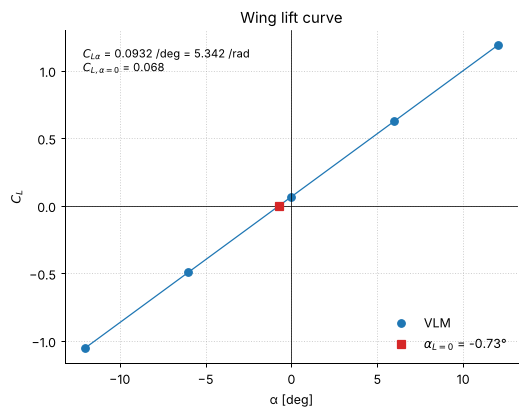

In [4]:
fit = v.fit_lift_curve(sol)
print(f"CL_alpha    = {fit.slope_per_deg:.4f} /deg = {fit.slope_per_rad:.3f} /rad")
print(f"CL(alpha=0) = {fit.cl_at_zero_alpha:.4f}")
print(f"alpha_L=0   = {fit.zero_lift_alpha_deg:.3f} deg")
plots.lift_curve(sol, fit);

## 4. Basic and additional lift

Because the problem is linear, the load splits into a basic part (camber and twist, at C<sub>L</sub> = 0)
and an additional part per unit C<sub>L</sub>.

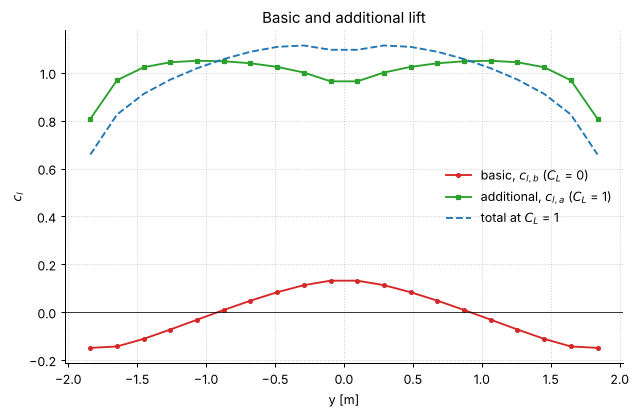

In [5]:
y, cl_b, cl_a = v.basic_additional_lift(wing)
plots.basic_additional(y, cl_b, cl_a);

## 5. Induced drag and pitching moment

Induced drag is evaluated in the Trefftz plane. The pitching moment is taken about the root leading
edge and transferred to the aerodynamic center.

alpha =   -12°  CL = -1.050  CDi = 0.0251  CM_0 =  1.115  CM_ac =  0.034
alpha =    -6°  CL = -0.491  CDi = 0.0063  CM_0 =  0.545  CM_ac =  0.040
alpha =     0°  CL =  0.068  CDi = 0.0007  CM_0 = -0.026  CM_ac =  0.045
alpha =     6°  CL =  0.628  CDi = 0.0082  CM_0 = -0.596  CM_ac =  0.050
alpha =    12°  CL =  1.187  CDi = 0.0288  CM_0 = -1.166  CM_ac =  0.055


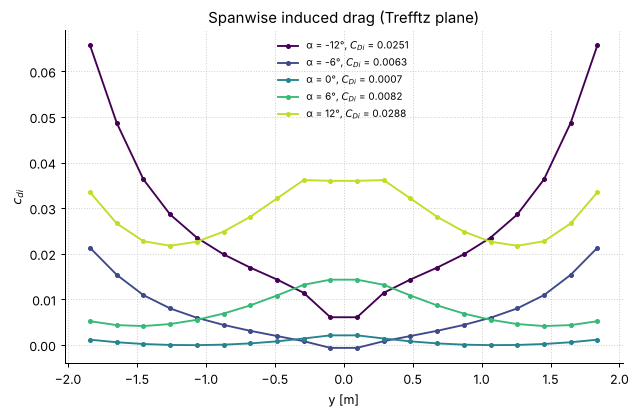

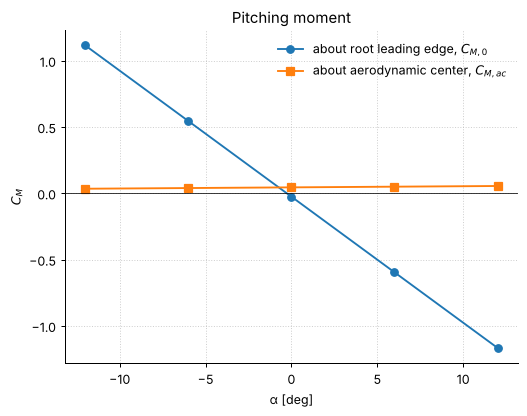

In [6]:
for a, CL, CDi, CM0, CMac in zip(alphas, sol.CL, sol.CDi, sol.CM_origin, sol.CM_ac):
    print(f"alpha = {a:5.0f}°  CL = {CL:6.3f}  CDi = {CDi:.4f}  CM_0 = {CM0:6.3f}  CM_ac = {CMac:6.3f}")
plots.induced_drag(sol)
plots.pitching_moment(sol);

## 6. Comparison with XFLR5

The XFLR5 export uses the same 20 spanwise stations, so the two can be compared point by point.

mean c_l offset (VLM - XFLR5): [0.2   0.235 0.241 0.243 0.265]
lift slope: VLM 0.0932, XFLR5 0.0909 /deg


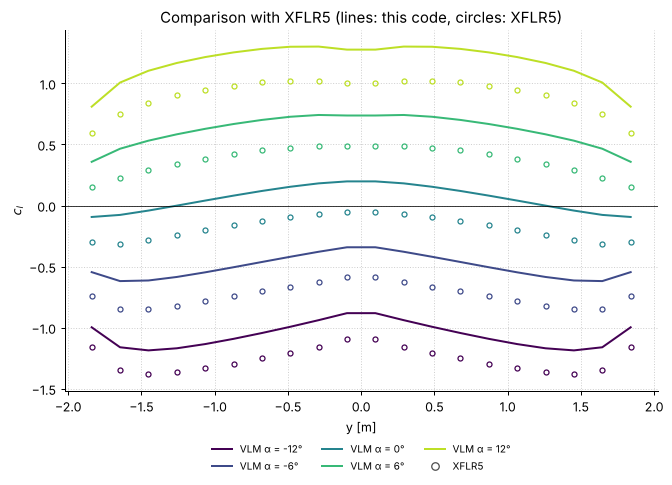

In [7]:
y_x, cl_x = v.load_xflr5()
offset = [np.mean(sol.cl[:, k] - cl_x[a]) for k, a in enumerate(alphas)]
m = sol.mesh
CL_x = [np.sum(cl_x[a] * m.chord_mid * m.dy) / wing.area for a in alphas]
slope_x = np.polyfit(alphas, CL_x, 1)[0]
print("mean c_l offset (VLM - XFLR5):", np.round(offset, 3))
print(f"lift slope: VLM {fit.slope_per_deg:.4f}, XFLR5 {slope_x:.4f} /deg")
plots.xflr5_comparison(sol, y_x, cl_x);

The distributions have the same shape, including the root dip, and the lift slopes agree within 3 %.
There is a near-constant offset of about 0.2 in c<sub>l</sub>, which shows up as a different zero-lift
angle. A likely source is the camber model: this code uses a single camber slope at 3c/4, while XFLR5
panels the actual mean line.

## 7. Mesh convergence

   4 panels  CL = 0.6394    0.118 ms
  10 panels  CL = 0.6336    0.124 ms
  20 panels  CL = 0.6277    0.127 ms
  40 panels  CL = 0.6232    0.216 ms
  80 panels  CL = 0.6207    0.521 ms
 120 panels  CL = 0.6199    1.014 ms
 160 panels  CL = 0.6194    1.685 ms
 320 panels  CL = 0.6188   11.956 ms


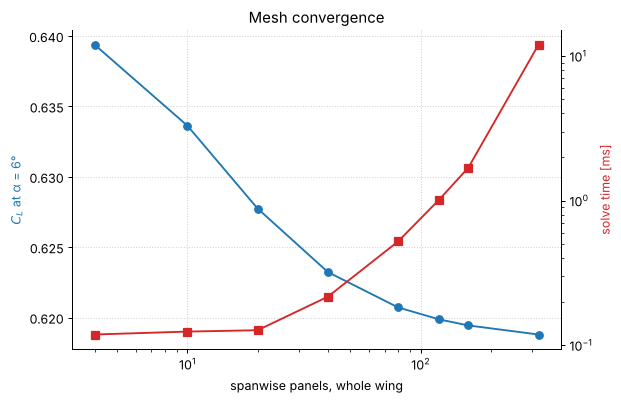

In [8]:
conv = v.mesh_convergence(wing)
for p in conv:
    print(f"{p.n_panels:4d} panels  CL = {p.CL:.4f}  {1e3 * p.seconds:7.3f} ms")
plots.mesh_convergence(conv);

## 8. Stall redesign

Goal: the c<sub>l</sub> peak at α = 15° (proxy for stall onset under a spanwise-uniform c<sub>l,max</sub>)
must lie within 40 % of the semispan, with dc<sub>l</sub>/dy ≤ −0.2 m⁻¹ just outboard of it. The search
holds the area at 1 m² and varies aspect ratio, quarter-chord sweep, taper, tip twist and airfoil.

baseline: onset at 25% of semispan, dCl/dy = -0.069 /m  -> gradient target not met
1529 feasible designs. Closest to the baseline:
  NACA 0012  A = 11.5  Λc/4 =  3.0°  λ = 1.00  ε = -8.0°  onset 5%  dCl/dy = -0.200  cost 1.127
  NACA 0012  A = 13.5  Λc/4 =  5.0°  λ = 1.00  ε = -9.0°  onset 5%  dCl/dy = -0.200  cost 1.133
  NACA 0012  A = 11.0  Λc/4 =  3.0°  λ = 1.00  ε = -8.0°  onset 5%  dCl/dy = -0.201  cost 1.135
  NACA 0012  A = 13.0  Λc/4 =  5.0°  λ = 1.00  ε = -9.0°  onset 5%  dCl/dy = -0.201  cost 1.137
  NACA 0012  A = 12.5  Λc/4 =  5.0°  λ = 1.00  ε = -9.0°  onset 5%  dCl/dy = -0.201  cost 1.141


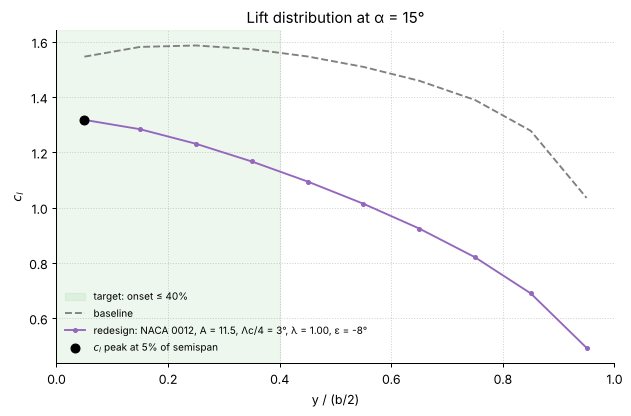

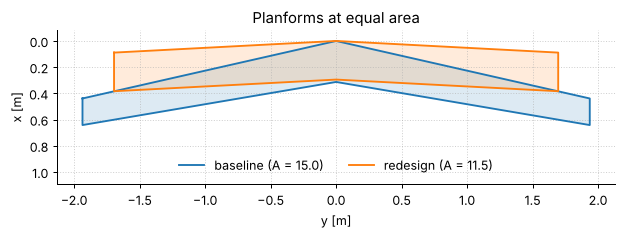

In [9]:
crit = v.StallCriteria()
base15 = v.solve(wing, crit.alpha_deg)
onset, grad, _ = v.stall_onset(base15.mesh.y_mid, base15.cl[:, 0], wing.semispan)
print(f"baseline: onset at {onset:.0%} of semispan, dCl/dy = {grad:.3f} /m  -> gradient target not met")

cands = v.search(wing, criteria=crit)
print(f"{len(cands)} feasible designs. Closest to the baseline:")
for c in cands[:5]:
    w = c.wing
    print(
        f"  NACA {w.airfoil}  A = {w.aspect_ratio:4.1f}  Λc/4 = {w.sweep_c4_deg:4.1f}°  λ = {w.taper:.2f}  "
        f"ε = {w.tip_twist_deg:4.1f}°  onset {c.onset:.0%}  dCl/dy = {c.gradient:.3f}  cost {c.cost:.3f}"
    )
best = cands[0]
plots.optimized_lift(best, crit, base15)
plots.planform_comparison(wing, best.wing);